# GRADIEND: compare features

Every GRADIEND model learns one feature. Comparing many models shows how features relate inside the base model.
This notebook needs no training: it loads 45 models from the [GRADIEND package paper](https://arxiv.org/abs/2602.23993) from the Hugging Face Hub.
They cover German articles (gender and case), English gender, English pronouns, sentiment, race and religion in multilingual BERT.
The same features for Qwen2.5-0.5B are in `aieng-lab/gradiend-qwen2.5-0.5b-features`; set `REPO` below to compare them instead.

```
pip install gradiend[recommended]
```

In [1]:
import sys

if "google.colab" in sys.modules:  # on Colab: install the package first
    !pip install -q "gradiend[recommended]"

In [2]:
from pathlib import Path

from huggingface_hub import snapshot_download

from gradiend.comparison import compute_anchor_aligned_encoding_matrix, load_saved_cross_encoding_inputs
from gradiend.model import ParamMappedGradiendModel

REPO = "aieng-lab/gradiend-multilingual-bert-features"  # or "aieng-lab/gradiend-qwen2.5-0.5b-features"
root = Path(snapshot_download(REPO))

pair_by_id, source_by_id, encoder_summary = load_saved_cross_encoding_inputs(root)  # class pair, source and cached encodings per model
models = {run_id: ParamMappedGradiendModel.from_pretrained(root / run_id / "model") for run_id in pair_by_id}
print(len(models), "models, e.g.", list(models)[:3])

Fetching 500 files:   0%|          | 0/500 [00:00<?, ?it/s]

45 models, e.g. ['gender_de_fem_acc_fem_dat', 'gender_de_fem_acc_fem_gen', 'gender_de_fem_acc_masc_acc']


In [3]:
# group the models and their classes by feature family for the plots
families = {"German articles": "gender_de_", "Gender": "gender_en", "Pronouns": "pronoun_", "Sentiment": "sentiment_", "Race": "race_", "Religion": "religion_"}
model_groups = {name: [i for i in models if i.startswith(prefix)] for name, prefix in families.items()}
class_groups = {name: list(dict.fromkeys(c for i in ids for c in pair_by_id[i])) for name, ids in model_groups.items()}
labels = {i: "\u21c4".join(pair) for i, pair in pair_by_id.items()}

## Top-k overlap: which weights does a feature use?

GRADIEND's decoder says which weights of the base model change when the feature changes. The **top-k overlap** of two models is the share of their 1000 most important weights that both have in common.
It is a direct comparison in weight space: related features should use the same weights. Three pronoun models as a Venn diagram:

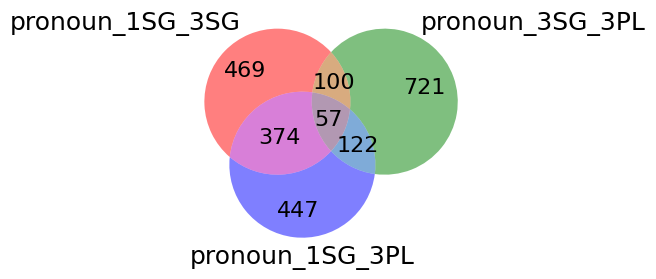

{'per_model': {'pronoun_1SG_3SG': [164740067,
   164581859,
   173469155,
   164498147,
   135944643,
   135941571,
   171881699,
   171543779,
   171433187,
   171897059,
   112410,
   171790307,
   112335,
   135919299,
   157208291,
   171935459,
   135954627,
   171669731,
   92205766,
   112149,
   165669347,
   164468195,
   157361123,
   164722403,
   164618723,
   164676323,
   171765731,
   171475427,
   171456227,
   164650979,
   172610531,
   171930851,
   164468963,
   171496163,
   157450979,
   157651427,
   157482467,
   164826083,
   172602851,
   157215971,
   164507363,
   157460195,
   157183715,
   171570659,
   164627939,
   164362211,
   164687075,
   171691235,
   164465123,
   164709347,
   164751587,
   171610595,
   171459299,
   164386019,
   164503523,
   157603811,
   173498339,
   164574947,
   171370211,
   164354531,
   164519651,
   174068195,
   171902435,
   171837155,
   157470179,
   164487395,
   171804899,
   135946947,
   164427491,
   164773859

In [4]:
from gradiend import plot_topk_overlap_venn

plot_topk_overlap_venn({i: models[i] for i in ["pronoun_1SG_3SG", "pronoun_3SG_3PL", "pronoun_1SG_3PL"]}, topk=1000)

All 45 models as a heatmap (percent of the top-1000 weights shared):

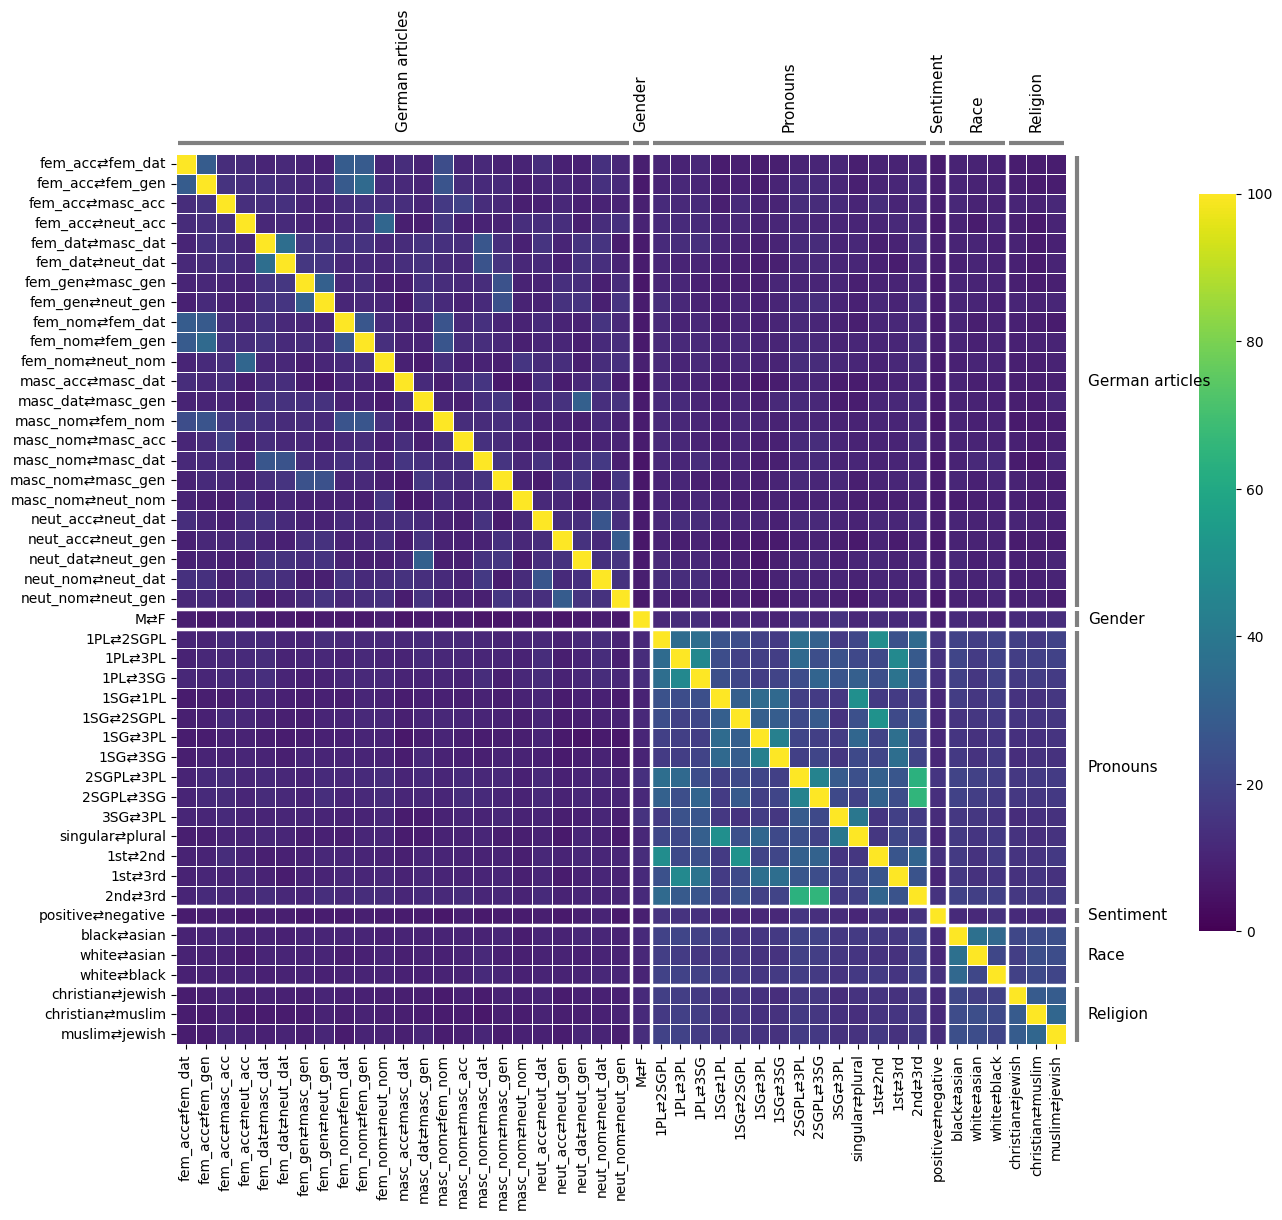

{'measure': 'topk_overlap',
 'model_ids': ['gender_de_fem_acc_fem_dat',
  'gender_de_fem_acc_fem_gen',
  'gender_de_fem_acc_masc_acc',
  'gender_de_fem_acc_neut_acc',
  'gender_de_fem_dat_masc_dat',
  'gender_de_fem_dat_neut_dat',
  'gender_de_fem_gen_masc_gen',
  'gender_de_fem_gen_neut_gen',
  'gender_de_fem_nom_fem_dat',
  'gender_de_fem_nom_fem_gen',
  'gender_de_fem_nom_neut_nom',
  'gender_de_masc_acc_masc_dat',
  'gender_de_masc_dat_masc_gen',
  'gender_de_masc_nom_fem_nom',
  'gender_de_masc_nom_masc_acc',
  'gender_de_masc_nom_masc_dat',
  'gender_de_masc_nom_masc_gen',
  'gender_de_masc_nom_neut_nom',
  'gender_de_neut_acc_neut_dat',
  'gender_de_neut_acc_neut_gen',
  'gender_de_neut_dat_neut_gen',
  'gender_de_neut_nom_neut_dat',
  'gender_de_neut_nom_neut_gen',
  'gender_en',
  'pronoun_1PL_2SGPL',
  'pronoun_1PL_3PL',
  'pronoun_1PL_3SG',
  'pronoun_1SG_1PL',
  'pronoun_1SG_2SGPL',
  'pronoun_1SG_3PL',
  'pronoun_1SG_3SG',
  'pronoun_2SGPL_3PL',
  'pronoun_2SGPL_3SG',
  'p

In [5]:
from gradiend import plot_topk_overlap_heatmap

order = [i for ids in model_groups.values() for i in ids]
plot_topk_overlap_heatmap(
    models, topk=1000, part="decoder-weight", value="intersection_frac", order=order, pretty_groups=model_groups,
    row_label_mapping=labels, column_label_mapping=labels, figsize=(14, 12), annot=False, percentages=True,
)

Models of the same family overlap most (German articles with the same surface form, English pronouns); unrelated features share about 10 %.

## Cross-encoding: does one feature respond to another?

Top-k overlap says nothing about what a model *does*. **Cross-encoding** does: it feeds the test examples of a *probe* feature (column) through the GRADIEND models of an *orienting* feature (row) and reports the encoded value.
+100 / -100 means the probe is encoded like the model's own feature, in the same or the opposite direction; 0 means no response.
The two views are complementary: overlap compares the parameters, cross-encoding compares the behaviour. The encodings were computed once and are read from the downloaded files.

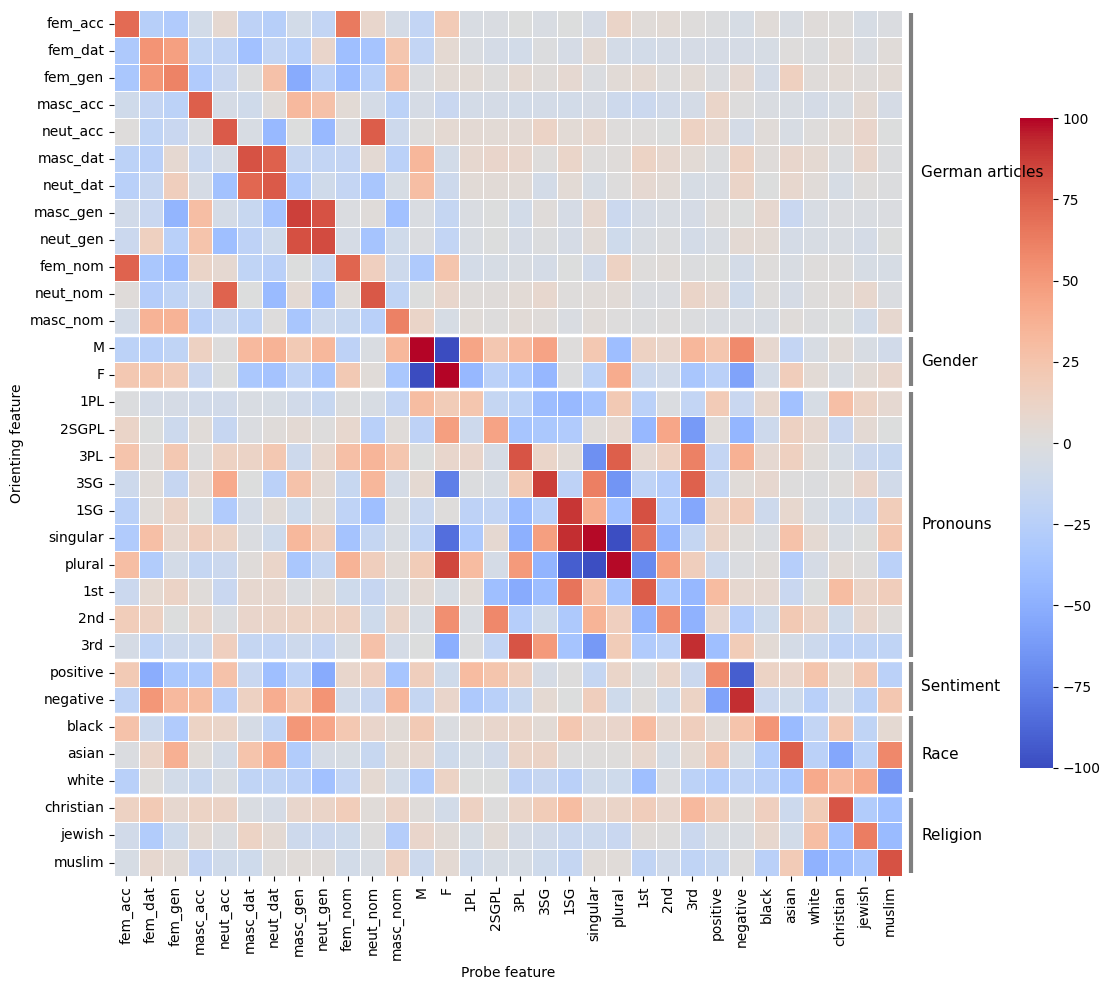

{'measure': 'anchor_aligned_encoding_factual_mean',
 'model_ids': ['fem_acc',
  'fem_dat',
  'fem_gen',
  'masc_acc',
  'neut_acc',
  'masc_dat',
  'neut_dat',
  'masc_gen',
  'neut_gen',
  'fem_nom',
  'neut_nom',
  'masc_nom',
  'M',
  'F',
  '1PL',
  '2SGPL',
  '3PL',
  '3SG',
  '1SG',
  'singular',
  'plural',
  '1st',
  '2nd',
  '3rd',
  'positive',
  'negative',
  'black',
  'asian',
  'white',
  'christian',
  'jewish',
  'muslim'],
 'column_ids': ['fem_acc',
  'fem_dat',
  'fem_gen',
  'masc_acc',
  'neut_acc',
  'masc_dat',
  'neut_dat',
  'masc_gen',
  'neut_gen',
  'fem_nom',
  'neut_nom',
  'masc_nom',
  'M',
  'F',
  '1PL',
  '2SGPL',
  '3PL',
  '3SG',
  '1SG',
  'singular',
  'plural',
  '1st',
  '2nd',
  '3rd',
  'positive',
  'negative',
  'black',
  'asian',
  'white',
  'christian',
  'jewish',
  'muslim'],
 'matrix': [[70.75564869035802,
   -25.128368654644444,
   -29.517551456057628,
   -8.168933016485445,
   6.407048793820043,
   -21.21339112533914,
   -25.59036437

In [6]:
from gradiend.visualizer.heatmaps import plot_comparison_heatmap

classes = [c for cs in class_groups.values() for c in cs]
cross_encoding = compute_anchor_aligned_encoding_matrix(
    pair_by_id=pair_by_id, encoder_summary=encoder_summary, feature_classes=classes, column_ids=classes, source_by_id=source_by_id,
)
plot_comparison_heatmap(
    cross_encoding, order=classes, pretty_groups=class_groups, cmap="coolwarm", vmin=-1, vmax=1, percentages=True,
    figsize=(12, 10), annot=False, xlabel="Probe feature", ylabel="Orienting feature",
)

The block structure is visible in both views: gender (M/F) and the pronoun features respond to each other, and German articles form blocks by case.
To train GRADIEND models for your own features, see the [spelling notebook](https://github.com/aieng-lab/gradiend/blob/main/gradiend/examples/demo/04_learn_your_own_feature.ipynb); the script `experiments/multilingual_gradiend_demo.py` trained all 45 models shown here.